# Analysis of Argentinian climate

This notebook shows how to study different aspects of the Argentinian climate in order to create a PowerPoint presentation that talks about it and how it is currently changing.

## Temperature

In this section, we'll analyse how the temperature changed during the Industrial Era of humanity.

In [2]:
import xarray

filename = "data/tas_Amon_EC-Earth_historical_r8i1p1_185001-201212.year.nc"
data = xarray.open_dataset(filename)
data

<xarray.Dataset> Size: 33MB
Dimensions:    (time: 163, bnds: 2, lon: 320, lat: 160)
Coordinates:
  * time       (time) datetime64[ns] 1kB 1850-07-01T06:00:00 ... 2012-07-01T0...
  * lon        (lon) float64 3kB 0.0 1.125 2.25 3.375 ... 356.6 357.8 358.9
  * lat        (lat) float64 1kB -89.14 -88.03 -86.91 ... 86.91 88.03 89.14
    height     float64 8B ...
Dimensions without coordinates: bnds
Data variables:
    time_bnds  (time, bnds) datetime64[ns] 3kB ...
    lon_bnds   (lon, bnds) float64 5kB ...
    lat_bnds   (lat, bnds) float64 3kB ...
    tas        (time, lat, lon) float32 33MB ...
Attributes: (12/30)
    CDI:                    Climate Data Interface version ?? (http://mpimet....
    Conventions:            CF-1.4
    history:                Fri Nov 01 22:29:23 2019: cdo yearmean tas_Amon_E...
    source:                 EC-Earth 2.3 (2011); atmosphere: IFS (cy31R1+modi...
    institution:            EC-Earth (European Earth System Model)
    institute_id:           ICHEC
    ...                     ...
    title:                  EC-Earth model output prepared for CMIP5 historical
    parent_experiment:      pre-industrial control
    modeling_realm:         atmos
    realization:            8
    cmor_version:           2.8.0
    CDO:                    Climate Data Operators version 1.9.3 (http://mpim...

In [25]:
temperature_data = data.tas

Selceting the data, we have to remeber that the `lat` $\in [-90, +90]$, while `lon` $\in [0, 360]$,so we cannot use negative values for the longitude of the Mendoza and San Juan provinces. Their latitude is comprised in $[-37, -28]$, while their longitude is in $[-70, -66]$.
We transform their longitude interval by adding 360 to each value:
$$
\begin{bmatrix}
-70 + 360 \\
-66 + 360
\end{bmatrix} = 
\begin{bmatrix}
290 \\
294
\end{bmatrix}
$$

In [18]:
provinces_temperature_data = temperature_data.sel(lat = slice(-37, -28), lon = slice(290, 294))

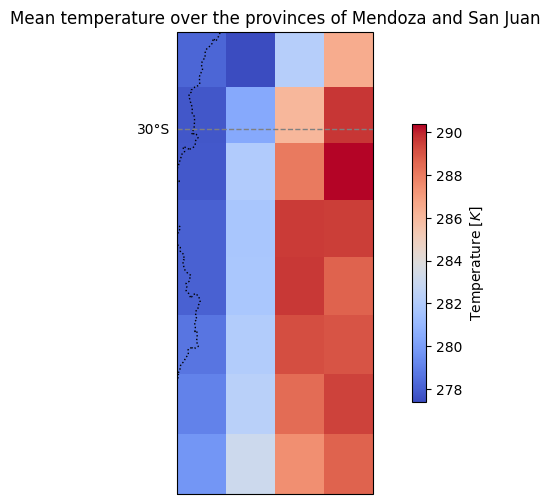

In [19]:
from util import plotmap
from matplotlib.pyplot import savefig

plotmap(provinces_temperature_data.mean(dim = "time"), 
        title = "Mean temperature over the provinces of Mendoza and San Juan", 
        national = True, proj = "mercator", cmap = "coolwarm", clabel = "Temperature $[K]$")
savefig("figures/mean_temperatures_over_provinces.png", dpi = 240, transparent = True)


Talking instead about the whole country of Argentina, we have that its `lat` $\in [-55, -20]$ and its `lon` $\in [-74, -56]$. Adding $360$ to each of the components of the latter we get: $[286, 304]$.

In [20]:
argentinian_temperature_data = temperature_data.sel(lat = slice(-55, -20), lon = slice(286, 304))

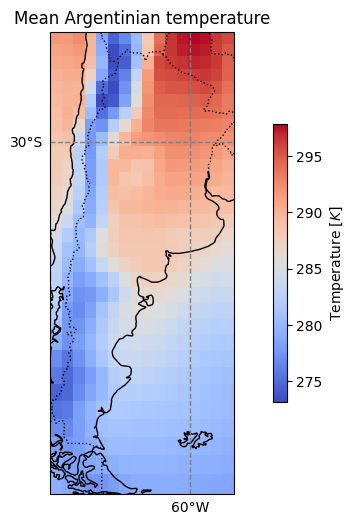

In [21]:
from util import plotmap

plotmap(argentinian_temperature_data.mean(dim = "time"), 
        title = "Mean Argentinian temperature", 
        national = True, proj = "mercator", cmap = "coolwarm", clabel = "Temperature $[K]$")
savefig("figures/mean_temperatures_over_Argentina.png", dpi = 240, transparent = True)

Let's plot the difference in mean temperature between the first decades after 1850 and the last decades of the dataset. The last year present in the data is 2012, so the last two decades will comprehend the year from 1992 to the end of the dataset.

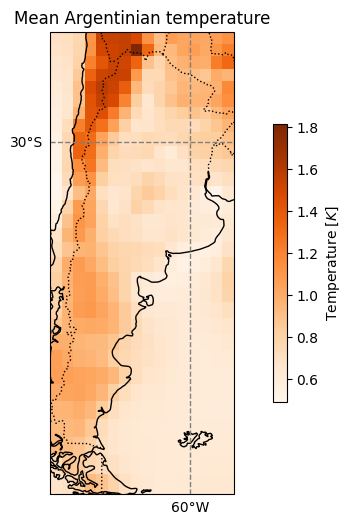

In [22]:
mean_argentinian_temperature_data_1850_1870 = argentinian_temperature_data.sel(time = slice("1850", "1870")).mean(dim = "time")
mean_argentinian_temperature_data_1992_2012 = argentinian_temperature_data.sel(time = slice("1992", "2012")).mean(dim = "time")

plotmap(mean_argentinian_temperature_data_1992_2012 - mean_argentinian_temperature_data_1850_1870, 
        title = "Mean Argentinian temperature", 
        national = True, proj = "mercator", cmap = "Oranges", clabel = "Temperature $[K]$")



## Precipitation

In this section we'll analyse how the precipitation changed in the decades.

In [1]:
import xarray

filename = "data/ERA5/total_precipitation/ERA5_total_precipitation_mon.year.nc"
data = xarray.open_dataset(filename)
data

<xarray.Dataset> Size: 18MB
Dimensions:    (time: 71, bnds: 2, lon: 360, lat: 180)
Coordinates:
  * time       (time) datetime64[ns] 568B 1950-07-01T05:30:00 ... 2020-07-01T...
  * lon        (lon) float64 3kB 0.0 1.0 2.0 3.0 4.0 ... 356.0 357.0 358.0 359.0
  * lat        (lat) float64 1kB -89.5 -88.5 -87.5 -86.5 ... 86.5 87.5 88.5 89.5
Dimensions without coordinates: bnds
Data variables:
    time_bnds  (time, bnds) datetime64[ns] 1kB ...
    tp         (time, lat, lon) float32 18MB ...
Attributes:
    CDI:          Climate Data Interface version 2.0.4 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    institution:  European Centre for Medium-Range Weather Forecasts
    history:      Fri Dec 22 14:27:42 2023: cdo yearmean /data/scratch/avacca...
    frequency:    year
    CDO:          Climate Data Operators version 2.0.4 (https://mpimet.mpg.de...

In [5]:
precipitation = data.tp
precipitation

type: 'Dataset' object has no attribute 'tp'

## Why doesn't the code above work?

In [16]:
import xarray

filename = "data/cmip5/models/EC-Earth/pr/historical/pr_Amon_EC-Earth_historical_r8i1p1_185001-201212.year.nc"
data = xarray.open_dataset(filename)

In [39]:
total_precipitation = data.pr
total_precipitation

<xarray.DataArray 'pr' (time: 163, lat: 160, lon: 320)> Size: 33MB
array([[[1.741372e-06, 1.735895e-06, ..., 1.755981e-06, 1.748677e-06],
        [1.428538e-06, 1.418070e-06, ..., 1.463997e-06, 1.446267e-06],
        ...,
        [5.489204e-06, 5.489896e-06, ..., 5.464437e-06, 5.476820e-06],
        [5.301459e-06, 5.314425e-06, ..., 5.302390e-06, 5.301925e-06]],

       [[1.673569e-06, 1.668728e-06, ..., 1.687846e-06, 1.680708e-06],
        [1.418265e-06, 1.408798e-06, ..., 1.449052e-06, 1.433659e-06],
        ...,
        [5.466989e-06, 5.482731e-06, ..., 5.418360e-06, 5.442675e-06],
        [5.214842e-06, 5.224237e-06, ..., 5.221626e-06, 5.218231e-06]],

       ...,

       [[2.297877e-06, 2.292256e-06, ..., 2.310149e-06, 2.304012e-06],
        [1.801022e-06, 1.791327e-06, ..., 1.835883e-06, 1.818452e-06],
        ...,
        [7.066177e-06, 7.072006e-06, ..., 7.067214e-06, 7.066694e-06],
        [7.177742e-06, 7.183018e-06, ..., 7.171830e-06, 7.174786e-06]],

       [[1.709513e-06, 1.707165e-06, ..., 1.718804e-06, 1.714159e-06],
        [1.349655e-06, 1.343661e-06, ..., 1.374460e-06, 1.362058e-06],
        ...,
        [6.620059e-06, 6.637873e-06, ..., 6.561016e-06, 6.590537e-06],
        [6.279725e-06, 6.270799e-06, ..., 6.283739e-06, 6.281731e-06]]],
      dtype=float32)
Coordinates:
  * time     (time) datetime64[ns] 1kB 1850-07-01T06:00:00 ... 2012-07-01T06:...
  * lon      (lon) float64 3kB 0.0 1.125 2.25 3.375 ... 355.5 356.6 357.8 358.9
  * lat      (lat) float64 1kB -89.14 -88.03 -86.91 -85.79 ... 86.91 88.03 89.14
Attributes:
    standard_name:     precipitation_flux
    long_name:         Precipitation
    units:             kg m-2 s-1
    comment:           at surface; includes both liquid and solid phases from...
    original_name:     TP=LSP+CP
    cell_methods:      time: mean (interval: 3 hours)
    cell_measures:     area: areacella
    history:           2011-12-16T16:40:57Z altered by CMOR: replaced missing...
    associated_files:  baseURL: http://cmip-pcmdi.llnl.gov/CMIP5/dataLocation...

The `total_precipitation` is expressed in $kg \cdot m^{-2} \cdot s^{-1}$, therefore we firstly transform the unit of measure in $mm/day$ by multiplying everything by $86400$ which is the number of seconds in a day.

In [40]:
total_precipitation = total_precipitation * 86400
total_precipitation.attrs = total_precipitation.attrs.copy()
total_precipitation.attrs["units"] = "mm/day"
total_precipitation

<xarray.DataArray 'pr' (time: 163, lat: 160, lon: 320)> Size: 67MB
array([[[0.15045456, 0.14998134, 0.14950811, ..., 0.15234792,
         0.1517168 , 0.15108568],
        [0.12342571, 0.12252127, 0.12161687, ..., 0.12802106,
         0.12648937, 0.12495751],
        [0.10761898, 0.10672499, 0.10583118, ..., 0.11121035,
         0.11001326, 0.1088161 ],
        ...,
        [0.45497558, 0.45602923, 0.45708299, ..., 0.45140603,
         0.45259605, 0.45378572],
        [0.47426722, 0.47432702, 0.47438666, ..., 0.47105737,
         0.47212736, 0.47319727],
        [0.45804607, 0.45916631, 0.46028644, ..., 0.45816685,
         0.45812654, 0.45808631]],

       [[0.14459639, 0.14417812, 0.14375978, ..., 0.14644668,
         0.14582987, 0.14521317],
        [0.12253812, 0.12172017, 0.12090234, ..., 0.12652799,
         0.12519805, 0.12386815],
        [0.10099479, 0.10065304, 0.10031115, ..., 0.10313804,
         0.10242361, 0.1017092 ],
...
        [0.61447097, 0.61727696, 0.62008298, ..., 0.61479063,
         0.61468404, 0.61457752],
        [0.61051767, 0.61102129, 0.61152503, ..., 0.61065169,
         0.61060725, 0.61056238],
        [0.62015693, 0.62061277, 0.62106893, ..., 0.61939077,
         0.61964611, 0.61990154]],

       [[0.1477019 , 0.14749904, 0.14729623, ..., 0.14890598,
         0.14850471, 0.1481033 ],
        [0.11661021, 0.11609234, 0.11557451, ..., 0.11982471,
         0.1187533 , 0.11768178],
        [0.09464764, 0.09436594, 0.09408412, ..., 0.09693726,
         0.09617402, 0.09541087],
        ...,
        [0.60814647, 0.60961364, 0.6110809 , ..., 0.59804308,
         0.60141084, 0.60477871],
        [0.57197311, 0.57351222, 0.57505126, ..., 0.56432088,
         0.56687175, 0.56942239],
        [0.54256823, 0.541797  , 0.5410257 , ..., 0.54308835,
         0.54291504, 0.54274154]]])
Coordinates:
  * time     (time) datetime64[ns] 1kB 1850-07-01T06:00:00 ... 2012-07-01T06:...
  * lon      (lon) float64 3kB 0.0 1.125 2.25 3.375 ... 355.5 356.6 357.8 358.9
  * lat      (lat) float64 1kB -89.14 -88.03 -86.91 -85.79 ... 86.91 88.03 89.14
Attributes:
    units:    mm/day

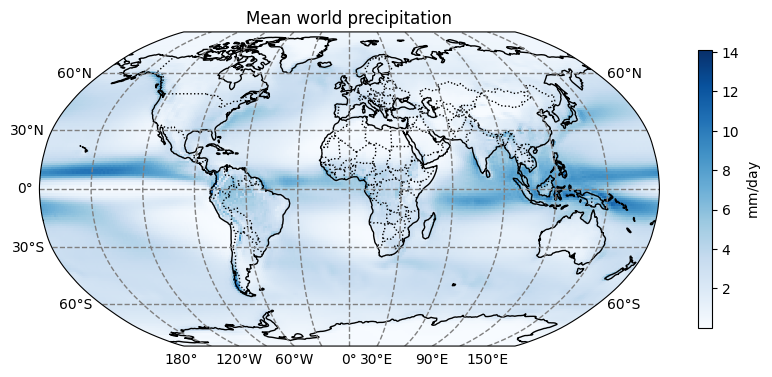

In [41]:
from util import plotmap

plotmap(total_precipitation.mean(dim = "time"), 
       title = "Mean world precipitation",
       national = True,
       proj = "robinson",
       cmap = "Blues",
       clabel = "mm$/$day")

We select the precipitation occurred only on Argentina:

In [42]:
argentinian_total_precipitation = total_precipitation.sel(lat = slice(-55, -20), lon = slice(286, 304))

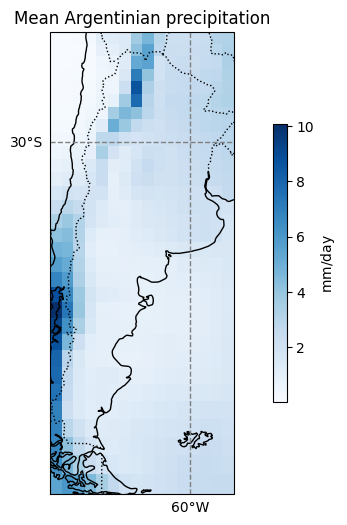

In [43]:
from util import plotmap

plotmap(argentinian_total_precipitation.mean(dim = "time"), 
       title = "Mean Argentinian precipitation",
       national = True,
       proj = "mercator",
       cmap = "Blues",
       clabel = "mm$/$day")

Let's analyse how the precipitation have changed in the decades above only above the provinces of Mendoza and San Juan:

Text(0.5, 1.0, 'Precipitation over the provinces of Mendoza and San Juan')

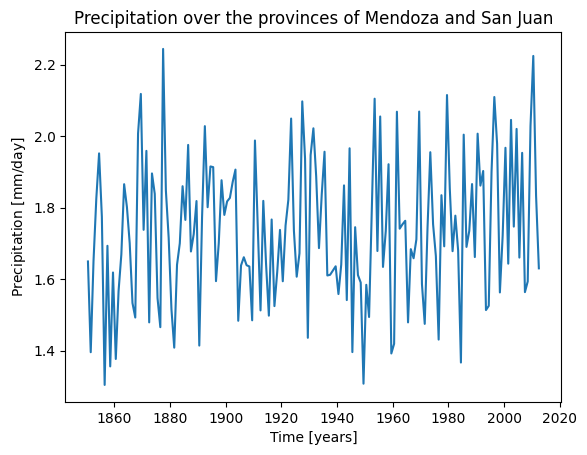

In [44]:
import matplotlib.pyplot as plt

provinces_total_precipitation = total_precipitation.sel(lat = slice(-37, -28), lon = slice(290, 294))
provinces_spatial_mean_precipitation = provinces_total_precipitation.mean(dim = ["lon", "lat"])

provinces_spatial_mean_precipitation.plot()
plt.xlabel("Time [years]")
plt.ylabel("Precipitation [mm$/$day]")
plt.title("Precipitation over the provinces of Mendoza and San Juan")

Let's search for a significance trend in the data:

In [45]:
from util import significance_trend

[slope, p_value] = significance_trend(provinces_spatial_mean_precipitation)
print("The slope of the linear regression line is:", slope)
print("The p-value for this slope is:", p_value)

The slope of the linear regression line is: 0.0006098812753124554
The p-value for this slope is: 0.063


Giving that the *p-value* found above is greater than 0.5, we have not found anything significant regarding the precipitation over the two Argentinian provinces. Let's investigate that of all of Argentina:

The slope of the linear regression line is: -7.047723131443864e-05
The p-value for this slope is: 0.712


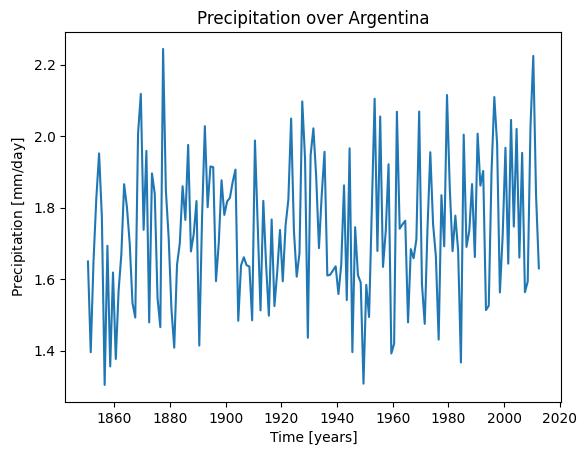

In [47]:
from util import significance_trend
import matplotlib.pyplot as plt

argentinian_spatial_mean_precipitation = argentinian_total_precipitation.mean(dim = ["lon", "lat"])

provinces_spatial_mean_precipitation.plot()
plt.xlabel("Time [years]")
plt.ylabel("Precipitation [mm$/$day]")
plt.title("Precipitation over Argentina")

[slope, p_value] = significance_trend(argentinian_spatial_mean_precipitation)
print("The slope of the linear regression line is:", slope)
print("The p-value for this slope is:", p_value)

The *p-value* is above 0.05, therefore, there is not any trend in the precipitation above all of Argentina.